In [1]:
!pip install roboflow ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 23.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 31.5 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [ultralytics]


In [2]:
from ultralytics import YOLO
model = YOLO('yolo26s.pt')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [3]:
from roboflow import Roboflow
rf = Roboflow(api_key="CFPqVUZkUzpq8L3aQPhe")
project = rf.workspace("noora-alkhalaqi").project("bahraini-currency-1ka60")
version = project.version(2)
dataset = version.download("yolo26")


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to bahraini-currency-2 in yolo26:: 100%|██████████| 2155/2155 [00:14<00:00, 150.32it/s]


In [4]:
model.train(data='/content/bahraini-currency-2/data.yaml', epochs= 5)

Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/bahraini-currency-2/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False,

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7f0e134bdfd0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.0

In [5]:
finetuned_model = YOLO('/content/runs/detect/train/weights/best.pt')

In [6]:
results = finetuned_model('/content/bahraini-currency-2/train/images/-_1_jpg.rf.ebab69c8f690fa904b56358290430585.jpg')


image 1/1 /content/bahraini-currency-2/train/images/-_1_jpg.rf.ebab69c8f690fa904b56358290430585.jpg: 640x320 2 0.5 BDs, 1 1 BD, 1 10 BD, 9.7ms
Speed: 3.3ms preprocess, 9.7ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 320)


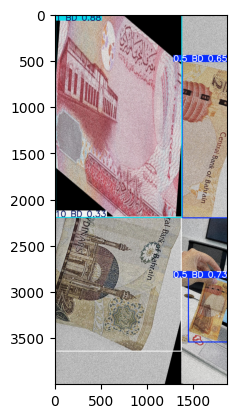

In [7]:
import matplotlib.pyplot as plt
plt.imshow(results[0].plot()[..., ::-1])

In [8]:
results = finetuned_model('/content/bahraini-currency-2/valid/images/1000236038_jpg.rf.0c685201157e27e2f48fb3c94e5a802f.jpg')


image 1/1 /content/bahraini-currency-2/valid/images/1000236038_jpg.rf.0c685201157e27e2f48fb3c94e5a802f.jpg: 640x320 1 50 fils, 12.8ms
Speed: 2.4ms preprocess, 12.8ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 320)


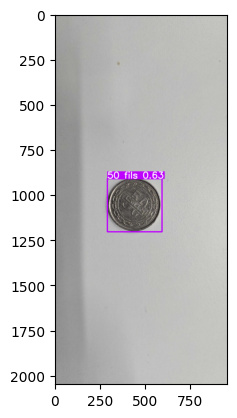

In [9]:
import matplotlib.pyplot as plt
plt.imshow(results[0].plot()[..., ::-1])

In [10]:
finetuned_model = YOLO('/content/runs/detect/train/weights/last.pt')

finetuned_model.train(data='/content/bahraini-currency-2/data.yaml', epochs= 10)

Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/bahraini-currency-2/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/runs/detect/train/weights/last.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-2, nbs=64, nm

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7f0e13403ad0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.0

In [12]:
finetuned_model = YOLO('/content/runs/detect/train-2/weights/best.pt')

In [13]:
results = finetuned_model('/content/bahraini-currency-2/valid/images/1000236034_jpg.rf.7025382d5e85dda9afcc78124a2415f9.jpg')


image 1/1 /content/bahraini-currency-2/valid/images/1000236034_jpg.rf.7025382d5e85dda9afcc78124a2415f9.jpg: 640x320 1 50 fils, 15.5ms
Speed: 1.8ms preprocess, 15.5ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 320)


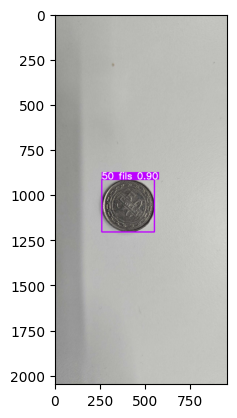

In [14]:
import matplotlib.pyplot as plt
plt.imshow(results[0].plot()[..., ::-1])

In [15]:
metrics = finetuned_model.val(split="test")

Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,469,050 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 182.9±113.1 MB/s, size: 357.4 KB)
val: Scanning /content/bahraini-currency-2/test/labels... 13 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 13/13 722.1it/s 0.0s
val: New cache created: /content/bahraini-currency-2/test/labels.cache
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 12, len(boxes) = 15. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 2.2it/s 0.5s
                   all         13         15      0.818       0.87      0.889      0.775
                0.5 BD          4          5      0.663    

In [17]:
print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)

Precision: 0.817611697178066
Recall: 0.8699999999999999
